# Question 2 - c

Hyperparameter selection - grid search over a certain set of parameters, judging based on the validation set, choosing the best one, and then reporting performance on the test set

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

In [2]:
wine = pd.read_csv("data/winequality-white.csv", sep=";")
X = wine.drop(columns="quality").to_numpy()
y = wine["quality"].to_numpy()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=2/3, random_state=0)
print(f"train {len(y_train)} | validation {len(y_val)} | test {len(y_test)}")

print("\nquality counts (all data):")
print(wine["quality"].value_counts().sort_index().to_string())
for name, y_split in [("validation", y_val), ("test", y_test)]:
    print(f"predict-the-training-mean MSE on {name}: {mean_squared_error(y_split, np.full(len(y_split), y_train.mean())):.4f}")

train 3428 | validation 490 | test 980

quality counts (all data):
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
predict-the-training-mean MSE on validation: 0.8090
predict-the-training-mean MSE on test: 0.8149


In [3]:
# Grid search helper
import time

def run_grid(make_model, grid):
    """Fit one model per hyperparameter combination on the training set; record validation and test MSE."""
    rows = []
    start = lap_start = time.perf_counter()
    for i, params in enumerate(ParameterGrid(grid)):
        model = make_model(params).fit(X_train, y_train)
        rows.append({**params,
                     "val_mse": mean_squared_error(y_val, model.predict(X_val)),
                     "test_mse": mean_squared_error(y_test, model.predict(X_test))})
        if (i + 1) % 100 == 0:
            now = time.perf_counter()
            print(f"  {i + 1} configurations done | last 100: {now - lap_start:.1f} s | total: {now - start:.1f} s")
            lap_start = now
    return pd.DataFrame(rows)

### RandomForestRegressor

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

Grid (4 × 5 × 5 × 5 = 500 combinations, which is more than the 490 in the validation set):
- `n_estimators` ∈ {25, 50, 100, 200}: number of trees averaged
- `max_depth` ∈ {4, 8, 12, 16, None}: maximum depth of each tree
- `min_samples_leaf` ∈ {1, 2, 4, 8, 16}: minimum number of training samples in a leaf
- `max_features` ∈ {0.2, 0.4, 0.6, 0.8, 1.0}: fraction of features considered at each split

In [4]:
rf_grid = {"n_estimators": [25, 50, 100, 200],
           "max_depth": [4, 8, 12, 16, None],
           "min_samples_leaf": [1, 2, 4, 8, 16],
           "max_features": [0.2, 0.4, 0.6, 0.8, 1.0]}
rf_results = run_grid(lambda p: RandomForestRegressor(**p, random_state=0, n_jobs=-1), rf_grid)

print(f"{len(rf_results)} random forest configurations")
rf_results.sort_values("val_mse").head(10)

  100 configurations done | last 100: 21.9 s | total: 21.9 s
  200 configurations done | last 100: 30.9 s | total: 52.8 s
  300 configurations done | last 100: 32.7 s | total: 85.5 s
  400 configurations done | last 100: 34.2 s | total: 119.8 s
  500 configurations done | last 100: 30.4 s | total: 150.2 s
500 random forest configurations


,max_depth,max_features,min_samples_leaf,n_estimators,val_mse,test_mse
463,NaN,0.8,1,200,0.379610,0.450242
422,NaN,0.4,1,100,0.380391,0.446974
423,NaN,0.4,1,200,0.380792,0.448866
403,NaN,0.2,1,200,0.381267,0.444632
443,NaN,0.6,1,200,0.381369,0.456010
303,16.0,0.2,1,200,0.381687,0.451688
342,16.0,0.6,1,100,0.381810,0.457404
446,NaN,0.6,2,100,0.381985,0.454869
442,NaN,0.6,1,100,0.382358,0.452278
343,16.0,0.6,1,200,0.382483,0.456968


### KNeighborsRegressor

https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html

Grid (100 × 2 × 3 = 600 combinations), features standardized using training statistics (KNN is distance-based):
- `n_neighbors` ∈ {1, …, 100}: number of neighbors averaged
- `weights` ∈ {uniform, distance}: equal weights, or closer neighbors weighted more
- `metric` ∈ {euclidean, manhattan, chebyshev}: how distance is measured

In [5]:
knn_grid = {"n_neighbors": list(range(1, 101)),
            "weights": ["uniform", "distance"],
            "metric": ["euclidean", "manhattan", "chebyshev"]}
knn_results = run_grid(lambda p: make_pipeline(StandardScaler(), KNeighborsRegressor(**p)), knn_grid)

print(f"{len(knn_results)} KNN configurations")
knn_results.sort_values("val_mse").head(10)

  100 configurations done | last 100: 11.5 s | total: 11.5 s
  200 configurations done | last 100: 12.5 s | total: 24.1 s
  300 configurations done | last 100: 11.0 s | total: 35.0 s
  400 configurations done | last 100: 13.2 s | total: 48.2 s
  500 configurations done | last 100: 13.2 s | total: 61.4 s
  600 configurations done | last 100: 16.8 s | total: 78.2 s
600 KNN configurations


,metric,n_neighbors,weights,val_mse,test_mse
231,manhattan,16,distance,0.400039,0.461478
227,manhattan,14,distance,0.402046,0.466464
229,manhattan,15,distance,0.402336,0.461975
223,manhattan,12,distance,0.405339,0.464042
211,manhattan,6,distance,0.405368,0.482763
233,manhattan,17,distance,0.405477,0.458605
225,manhattan,13,distance,0.406156,0.465963
259,manhattan,30,distance,0.408510,0.458149
263,manhattan,32,distance,0.408799,0.456858
257,manhattan,29,distance,0.408933,0.457925


### Empirical risk on validation vs test set

In [6]:
summary = []
for name, results in [("random forest", rf_results), ("KNN", knn_results)]:
    best = results.loc[results["val_mse"].idxmin()]
    gap = results["test_mse"] - results["val_mse"]
    top10 = results.nsmallest(10, "val_mse")
    summary.append({
        "model": name,
        "val MSE": best["val_mse"],
        "test MSE": best["test_mse"],
        "gap": best["test_mse"] - best["val_mse"],
        "mean gap (top 10 by val MSE)": (top10["test_mse"] - top10["val_mse"]).mean(),
        "mean gap (all configs)": gap.mean(),
        "best test MSE of any config": results["test_mse"].min(),
        "selected config's rank on test": int((results["test_mse"] < best["test_mse"]).sum()) + 1,
    })
pd.DataFrame(summary).set_index("model").round(4)

,val MSE,test MSE,gap,mean gap (top 10 by val MSE),mean gap (all configs),best test MSE of any config,selected config's rank on test
model,,,,,,,
random forest,0.3796,0.4502,0.0706,0.0706,0.0608,0.4437,6
KNN,0.4000,0.4615,0.0614,0.0581,0.0418,0.4510,127


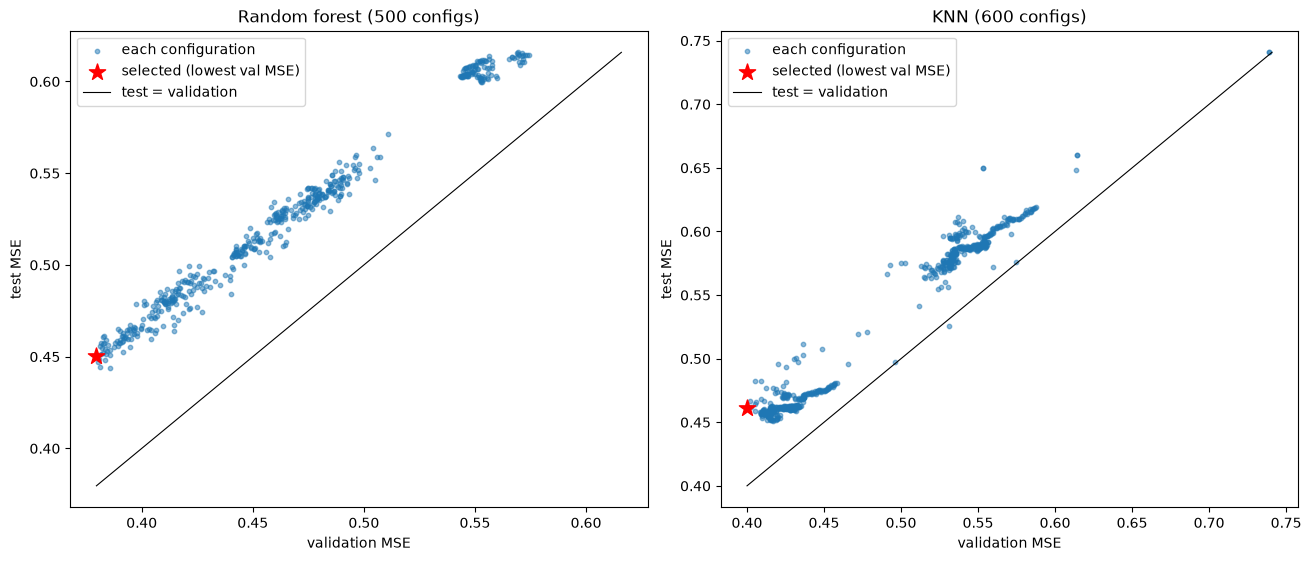

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
for ax, (name, results) in zip(axes, [("Random forest (500 configs)", rf_results), ("KNN (600 configs)", knn_results)]):
    best = results.loc[results["val_mse"].idxmin()]
    ax.scatter(results["val_mse"], results["test_mse"], s=10, alpha=0.5, label="each configuration")
    ax.scatter(best["val_mse"], best["test_mse"], s=150, marker="*", color="red", label="selected (lowest val MSE)")
    lims = [min(results["val_mse"].min(), results["test_mse"].min()), max(results["val_mse"].max(), results["test_mse"].max())]
    ax.plot(lims, lims, color="black", linewidth=0.8, label="test = validation")
    ax.set_xlabel("validation MSE")
    ax.set_ylabel("test MSE")
    ax.set_title(name)
    ax.legend()
plt.show()

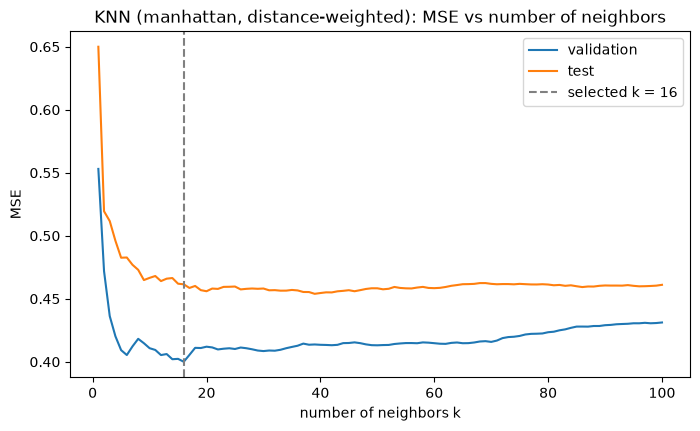

In [8]:
metric, weights = "manhattan", "distance"
subset = knn_results[(knn_results["metric"] == metric) & (knn_results["weights"] == weights)].sort_values("n_neighbors")
best_k = subset.loc[subset["val_mse"].idxmin(), "n_neighbors"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(subset["n_neighbors"], subset["val_mse"], label="validation")
ax.plot(subset["n_neighbors"], subset["test_mse"], label="test")
ax.axvline(best_k, color="gray", linestyle="--", label=f"selected k = {best_k}")
ax.set_xlabel("number of neighbors k")
ax.set_ylabel("MSE")
ax.set_title(f"KNN ({metric}, {weights}-weighted): MSE vs number of neighbors")
ax.legend()
plt.show()

The random forest best model outperforms the KNN model on both validation and test MSE, though the MSE scores are closer to each other - KNN models have a smaller gap between performance on the validation set and the test set. Generally, the empirical risk on the validation set is less than that on the test set, true across both model classes (see the scatterplot above). However, the models that we choose (using performance on the validation set) tend to have higher-than-average gaps between performance on the test and validation sets. This is not quite a $k \gg l$ case as discussed in 2b but we still have $k>l$ hence there is some degree of losing generalization because of the flexibility of the training settings we use.